# Step 7 — Thermal Conductivity Prediction (Regression)

## Objective

Train and compare multiple machine-learning regression models to estimate a product's thermal conductivity (`W/mK`) from other available product properties.

This is a **product-level material-property prediction experiment**. It is not a wall U-value calculation and does not replace the SpecSynth ThermalEngine or manufacturer documentation.

### Important data-leakage prevention

Thermal conductivity can be calculated from thermal resistance and thickness:

`thermal conductivity = thickness / thermal resistance`

Therefore, this experiment deliberately excludes:
- Thermal conductivity from the input features (it is the target).
- Thermal resistance.
- Thickness.

This prevents the model from being given values that can directly reveal the answer through the thermal-resistance relationship.

We will preserve the dataset's existing `recommended_split` assignments. We will train candidate models on the training split, select using validation MAE, and evaluate the selected model once on the untouched test split.

## 1. Imports and reproducibility

In [1]:
from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.base import clone
from sklearn.compose import TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    HistGradientBoostingRegressor,
    GradientBoostingRegressor,
    RandomForestRegressor
)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

NumPy: 2.0.1
Pandas: 3.0.3


## 2. Locate the SpecSynth project and load the ML dataset

In [2]:
def find_project_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    candidates = [start, *start.parents]
    for candidate in candidates:
        if (candidate / "04_Product_Dataset").exists():
            return candidate
    # Search common notebook execution locations as a fallback.
    fallback = Path(r"D:/02_LEARNING/02_Masters_IAAC_AI_Architecture/10-Term_01/03-Research Studio/SpecSynth_AI")
    if fallback.exists():
        return fallback
    raise FileNotFoundError(
        "Could not locate the SpecSynth_AI project root. "
        "Place this notebook inside the project or update the fallback path."
    )

PROJECT_ROOT = find_project_root()
DATA_VERSION_DIR = (
    PROJECT_ROOT / "04_Product_Dataset" / "10_Master_Database" /
    "SpecSynth_Master_Database_v1.0" / "source_data" / "v1.5.0"
)
CSV_PATH = DATA_VERSION_DIR / "ml" / "SpecSynth_ML_variants_v1.5.0.csv"

if not CSV_PATH.exists():
    raise FileNotFoundError(f"Dataset not found: {CSV_PATH}")

df = pd.read_csv(CSV_PATH)
print("Project root:", PROJECT_ROOT)
print("Dataset:", CSV_PATH)
print("Shape:", df.shape)
display(df.head())

Project root: D:\02_LEARNING\02_Masters_IAAC_AI_Architecture\10-Term_01\03-Research Studio\SpecSynth_AI
Dataset: D:\02_LEARNING\02_Masters_IAAC_AI_Architecture\10-Term_01\03-Research Studio\SpecSynth_AI\04_Product_Dataset\10_Master_Database\SpecSynth_Master_Database_v1.0\source_data\v1.5.0\ml\SpecSynth_ML_variants_v1.5.0.csv
Shape: (1941, 47)


,record_id,product_id,variant_id,material_category_group,material_family,category,manufacturer,market,record_origin,dataset_version_added,...,qa_flag_count,qa_flags,source_ids,split_group_id,target_thermal_conductivity_W_mK,target_density_kg_m3,target_specific_heat_J_kgK,target_gwp_a1_a3_kgco2e_m2,target_price_per_m2,recommended_split
0,ML_UNILIN_UTHERM_WALL_A_40MM,UNILIN_UTHERM_WALL_A,UNILIN_UTHERM_WALL_A_40MM,A_thermal_insulation,PIR,PIR insulation board,UNILIN Insulation,NaN,legacy_v1.2.0,1.2.0,...,0,NaN,SRC_UNILIN_DOP;SRC_UNILIN_TDS,UNILIN_UTHERM_WALL_A,0.022,32.0,NaN,NaN,NaN,train
1,ML_UNILIN_UTHERM_WALL_A_50MM,UNILIN_UTHERM_WALL_A,UNILIN_UTHERM_WALL_A_50MM,A_thermal_insulation,PIR,PIR insulation board,UNILIN Insulation,NaN,legacy_v1.2.0,1.2.0,...,0,NaN,SRC_UNILIN_DOP;SRC_UNILIN_TDS,UNILIN_UTHERM_WALL_A,0.022,32.0,NaN,NaN,NaN,train
2,ML_UNILIN_UTHERM_WALL_A_60MM,UNILIN_UTHERM_WALL_A,UNILIN_UTHERM_WALL_A_60MM,A_thermal_insulation,PIR,PIR insulation board,UNILIN Insulation,NaN,legacy_v1.2.0,1.2.0,...,0,NaN,SRC_UNILIN_DOP;SRC_UNILIN_TDS,UNILIN_UTHERM_WALL_A,0.022,32.0,NaN,NaN,NaN,train
3,ML_UNILIN_UTHERM_WALL_A_70MM,UNILIN_UTHERM_WALL_A,UNILIN_UTHERM_WALL_A_70MM,A_thermal_insulation,PIR,PIR insulation board,UNILIN Insulation,NaN,legacy_v1.2.0,1.2.0,...,0,NaN,SRC_UNILIN_DOP;SRC_UNILIN_TDS,UNILIN_UTHERM_WALL_A,0.022,32.0,NaN,NaN,NaN,train
4,ML_UNILIN_UTHERM_WALL_A_80MM,UNILIN_UTHERM_WALL_A,UNILIN_UTHERM_WALL_A_80MM,A_thermal_insulation,PIR,PIR insulation board,UNILIN Insulation,NaN,legacy_v1.2.0,1.2.0,...,0,NaN,SRC_UNILIN_DOP;SRC_UNILIN_TDS,UNILIN_UTHERM_WALL_A,0.022,32.0,NaN,NaN,NaN,train


### Outcome and conclusion

The correct SpecSynth v1.5.0 dataset loaded successfully: **1,941 rows × 47 columns**.

The notebook found the target column `target_thermal_conductivity_W_mK`. The original split contains 1,621 training, 186 validation and 134 test records. Of these, conductivity targets are available for 1,493 training, 174 validation and 114 test records.

**Conclusion:** The dataset and original split were located correctly. Twenty test records, 12 validation records and 128 training records do not have a conductivity target and are therefore not usable for this supervised regression experiment.

## 3. Identify target and original data splits

In [3]:
target_candidates = [
    "target_thermal_conductivity_W_mK",
    "thermal_conductivity_W_mK_target",
    "target_thermal_conductivity",
    "thermal_conductivity_W_mK"
]
TARGET = next((c for c in target_candidates if c in df.columns), None)
if TARGET is None:
    raise KeyError(
        "Could not find the thermal-conductivity target. "
        f"Available columns: {df.columns.tolist()}"
    )

SPLIT_COL = "recommended_split"
if SPLIT_COL not in df.columns:
    raise KeyError("The original recommended_split column is missing.")

print("Target column:", TARGET)
print("\nSplit counts:")
display(df[SPLIT_COL].value_counts(dropna=False).to_frame("records"))

print("\nTarget availability by split:")
display(
    df.groupby(SPLIT_COL)[TARGET]
      .agg(total="size", available="count", missing=lambda s: s.isna().sum())
)

Target column: target_thermal_conductivity_W_mK

Split counts:


,records
recommended_split,
train,1621
validation,186
test,134



Target availability by split:


,total,available,missing
recommended_split,,,
test,134,114,20
train,1621,1493,128
validation,186,174,12


### Outcome and conclusion

The target is `target_thermal_conductivity_W_mK`, measured in W/mK. The existing `recommended_split` assignments were preserved.

**Conclusion:** Keeping the original split avoids creating a new random partition that could separate related product variants differently from the dataset's established grouping. Only records with a known target are used for training and evaluation.

## 4. Select safe input features and prepare modelling records

In [4]:
# Exclude the target and variables that can directly reveal it through
# lambda = thickness / thermal resistance.
LEAKAGE_COLUMNS = {
    TARGET,
    "thermal_conductivity_W_mK",
    "target_thermal_conductivity_W_mK",
    "thermal_conductivity_W_mK_target",
    "thermal_resistance_m2K_W",
    "thickness_mm"
}

candidate_features = [
    "density_kg_m3",
    "specific_heat_J_kgK",
    "vapour_resistance_factor_mu",
    "compressive_strength_kPa",
    "tensile_strength_perpendicular_kPa",
    "mass_per_area_kg_m2",
    "Ug_W_m2K"
]
feature_columns = [
    c for c in candidate_features
    if c in df.columns and c not in LEAKAGE_COLUMNS
]

if not feature_columns:
    raise ValueError(
        "None of the safe candidate features were found. "
        "Inspect df.columns and update candidate_features."
    )

# Keep rows with a known target and an original train/validation/test assignment.
split_map = {
    "train": "train", "training": "train",
    "validation": "validation", "val": "validation",
    "test": "test", "testing": "test"
}
work = df.copy()
work["_split_normalized"] = (
    work[SPLIT_COL].astype(str).str.strip().str.lower().map(split_map)
)

work[TARGET] = pd.to_numeric(work[TARGET], errors="coerce")
for col in feature_columns:
    work[col] = pd.to_numeric(work[col], errors="coerce")

work = work[
    work["_split_normalized"].notna() &
    work[TARGET].notna()
].copy()

# Remove input columns with no observed values in the modelling population.
feature_columns = [
    c for c in feature_columns if work[c].notna().any()
]

if not feature_columns:
    raise ValueError("All candidate input features are empty.")

print("Selected safe features:", feature_columns)
print("Excluded leakage columns:", sorted(LEAKAGE_COLUMNS))
print("Eligible records:", len(work))
print("\nEligible records by split:")
display(work["_split_normalized"].value_counts().to_frame("records"))
print("\nFeature missingness:")
display((work[feature_columns].isna().mean() * 100).round(1).to_frame("missing_percent"))

Selected safe features: ['density_kg_m3', 'specific_heat_J_kgK', 'vapour_resistance_factor_mu', 'compressive_strength_kPa', 'tensile_strength_perpendicular_kPa', 'mass_per_area_kg_m2']
Excluded leakage columns: ['target_thermal_conductivity_W_mK', 'thermal_conductivity_W_mK', 'thermal_conductivity_W_mK_target', 'thermal_resistance_m2K_W', 'thickness_mm']
Eligible records: 1781

Eligible records by split:


,records
_split_normalized,
train,1493
validation,174
test,114



Feature missingness:


,missing_percent
density_kg_m3,85.3
specific_heat_J_kgK,93.1
vapour_resistance_factor_mu,65.0
compressive_strength_kPa,63.2
tensile_strength_perpendicular_kPa,65.2
mass_per_area_kg_m2,85.3


### Outcome and conclusion

Six safe input features were available and selected:

- Density
- Specific heat capacity
- Vapour resistance factor
- Compressive strength
- Tensile strength
- Mass per area

Thickness, thermal resistance and thermal conductivity were excluded to prevent direct target leakage. `Ug_W_m2K` was not retained because it had no usable observations in this modelling population.

The selected features have substantial missingness:

| Feature | Missing |
|---|---:|
| Density | 85.3% |
| Specific heat | 93.1% |
| Vapour resistance | 65.0% |
| Compressive strength | 63.2% |
| Tensile strength | 65.2% |
| Mass per area | 85.3% |

**Conclusion:** The leakage prevention is appropriate, but the model has limited information available for many products. Missing values are filled using medians learned from training data. This is a major limitation and should be considered when interpreting predictions.

## 5. Create train, validation and test datasets

In [5]:
train_df = work[work["_split_normalized"] == "train"].copy()
val_df = work[work["_split_normalized"] == "validation"].copy()
test_df = work[work["_split_normalized"] == "test"].copy()

if min(len(train_df), len(val_df), len(test_df)) == 0:
    raise ValueError(
        "One of train/validation/test is empty. "
        "Check the values in recommended_split."
    )

X_train = train_df[feature_columns]
y_train = train_df[TARGET].astype(float)

X_val = val_df[feature_columns]
y_val = val_df[TARGET].astype(float)

X_test = test_df[feature_columns]
y_test = test_df[TARGET].astype(float)

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)

print("\nTarget summary by split:")
display(work.groupby("_split_normalized")[TARGET].describe().round(4))

Training: (1493, 6) (1493,)
Validation: (174, 6) (174,)
Testing: (114, 6) (114,)

Target summary by split:


,count,mean,std,min,25%,50%,75%,max
_split_normalized,,,,,,,,
test,114.0,0.0608,0.0606,0.021,0.023,0.032,0.120,0.30
train,1493.0,0.0387,0.0306,0.020,0.031,0.034,0.037,0.35
validation,174.0,0.0355,0.0274,0.019,0.022,0.032,0.034,0.30


### Outcome and conclusion

After removing records without a target, the modelling dataset contains **1,781 records**:

| Split | Records |
|---|---:|
| Training | 1,493 |
| Validation | 174 |
| Test | 114 |

Target distribution differs between splits:

| Split | Mean λ (W/mK) | Median λ (W/mK) | Maximum λ |
|---|---:|---:|---:|
| Training | 0.0387 | 0.034 | 0.35 |
| Validation | 0.0355 | 0.032 | 0.30 |
| Test | 0.0608 | 0.032 | 0.30 |

**Conclusion:** The test set has a higher average conductivity than the training and validation sets, largely indicating that its target distribution is different. This can make test performance more difficult and less directly comparable with validation performance.

## 6. Define multiple regression models

In [6]:
models = {
    "Dummy Mean Baseline": DummyRegressor(strategy="mean"),
    "Linear Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),
    "Ridge Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=1.0))
    ]),
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestRegressor(
            n_estimators=400,
            min_samples_leaf=2,
            random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ]),
    "Extra Trees": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", ExtraTreesRegressor(
            n_estimators=400,
            min_samples_leaf=2,
            random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ]),
    "Gradient Boosting": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", GradientBoostingRegressor(
            n_estimators=200,
            learning_rate=0.04,
            max_depth=2,
            loss="huber",
            random_state=RANDOM_STATE
        ))
    ]),
    "Histogram Gradient Boosting": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", HistGradientBoostingRegressor(
            max_iter=250,
            learning_rate=0.05,
            max_leaf_nodes=15,
            l2_regularization=1.0,
            random_state=RANDOM_STATE
        ))
    ])
}

print("Candidate models:", len(models))
for model_name in models:
    print("-", model_name)

Candidate models: 7
- Dummy Mean Baseline
- Linear Regression
- Ridge Regression
- Random Forest
- Extra Trees
- Gradient Boosting
- Histogram Gradient Boosting


### Outcome and conclusion

Seven regression candidates were prepared: a mean baseline, Linear Regression, Ridge Regression, Random Forest, Extra Trees, Gradient Boosting and Histogram Gradient Boosting.

**Conclusion:** This gives us a useful comparison across a simple baseline, linear models and tree-based models. All candidates use the same training records and the same six input features, with imputation performed inside each model pipeline.

## 7. Train models and compare validation performance

In [7]:
def regression_metrics(y_true, y_pred):
    return {
        "MAE_W_mK": mean_absolute_error(y_true, y_pred),
        "RMSE_W_mK": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }

fitted_models = {}
validation_predictions = {}
validation_rows = []

for name, estimator in models.items():
    print("Training:", name)
    fitted = clone(estimator)
    fitted.fit(X_train, y_train)
    predictions = fitted.predict(X_val)

    fitted_models[name] = fitted
    validation_predictions[name] = predictions

    row = {"model": name}
    row.update(regression_metrics(y_val, predictions))
    validation_rows.append(row)

validation_comparison = pd.DataFrame(validation_rows).sort_values(
    ["MAE_W_mK", "RMSE_W_mK"],
    ascending=[True, True]
).reset_index(drop=True)

display(validation_comparison.round(5))

Training: Dummy Mean Baseline
Training: Linear Regression
Training: Ridge Regression
Training: Random Forest
Training: Extra Trees
Training: Gradient Boosting
Training: Histogram Gradient Boosting


,model,MAE_W_mK,RMSE_W_mK,R2
0,Extra Trees,0.00306,0.01044,0.85359
1,Gradient Boosting,0.00336,0.00869,0.89852
2,Random Forest,0.00388,0.01175,0.81448
3,Histogram Gradient Boosting,0.00460,0.01172,0.81522
4,Ridge Regression,0.01170,0.01658,0.63045
5,Linear Regression,0.01171,0.01659,0.62999
6,Dummy Mean Baseline,0.01296,0.02746,-0.01349


### Outcome and conclusion — actual validation results

| Model | MAE (W/mK) | RMSE (W/mK) | R² |
|---|---:|---:|---:|
| Extra Trees | **0.00306** | 0.01044 | 0.85359 |
| Gradient Boosting | 0.00336 | **0.00869** | **0.89852** |
| Random Forest | 0.00388 | 0.01175 | 0.81448 |
| Histogram Gradient Boosting | 0.00460 | 0.01172 | 0.81522 |
| Ridge Regression | 0.01170 | 0.01658 | 0.63045 |
| Linear Regression | 0.01171 | 0.01659 | 0.62999 |
| Dummy Mean Baseline | 0.01296 | 0.02746 | -0.01349 |

**Conclusion:** Extra Trees achieved the lowest validation MAE, while Gradient Boosting achieved the best RMSE and R². The mean baseline performed substantially worse than the leading tree models. The ranking depends on which error measure matters most: Extra Trees makes the smallest average absolute error, while Gradient Boosting has the lower squared-error measure and explains more validation variation.

## 8. Visualise validation model comparison

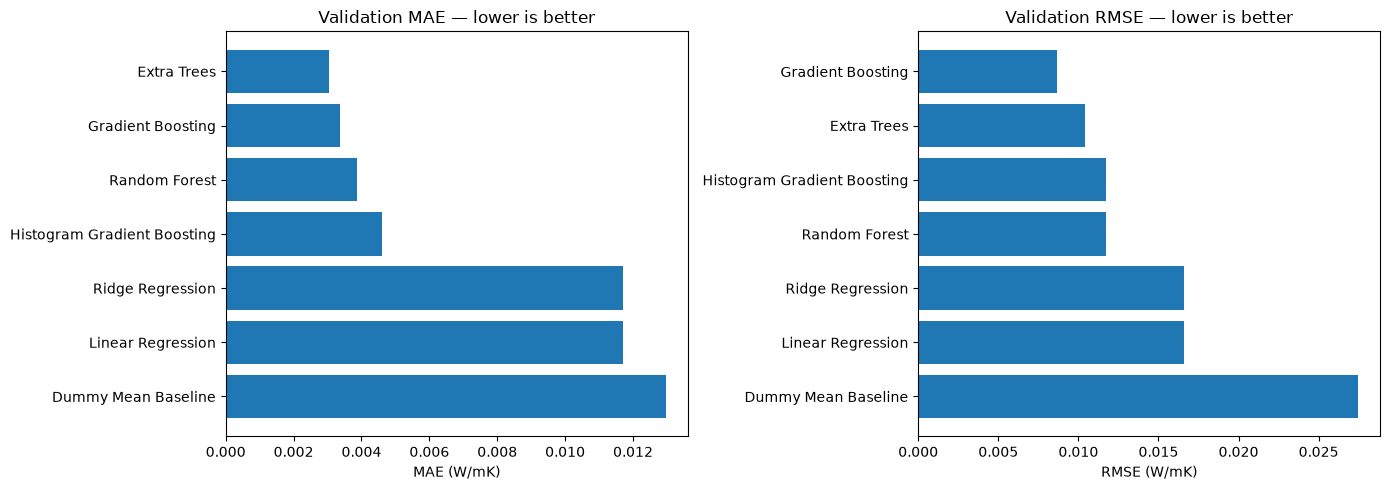

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_df = validation_comparison.sort_values("MAE_W_mK")
axes[0].barh(plot_df["model"], plot_df["MAE_W_mK"])
axes[0].invert_yaxis()
axes[0].set_xlabel("MAE (W/mK)")
axes[0].set_title("Validation MAE — lower is better")

plot_df2 = validation_comparison.sort_values("RMSE_W_mK")
axes[1].barh(plot_df2["model"], plot_df2["RMSE_W_mK"])
axes[1].invert_yaxis()
axes[1].set_xlabel("RMSE (W/mK)")
axes[1].set_title("Validation RMSE — lower is better")

plt.tight_layout()
plt.show()

### Outcome and conclusion

The charts reflect the numerical comparison: Extra Trees has the lowest MAE, while Gradient Boosting has the lowest RMSE.

**Conclusion:** The models are close on MAE, so the choice is not an overwhelming win for Extra Trees. Gradient Boosting's stronger RMSE and R² suggest it may handle the overall validation variation better. We retain the pre-declared selection rule of lowest MAE, with RMSE as tie-breaker, and record this trade-off for later review.

## 9. Select the best model using validation results

In [9]:
best_model_name = str(validation_comparison.iloc[0]["model"])
best_model = fitted_models[best_model_name]

print("Selected model:", best_model_name)
print("Validation metrics:")
display(validation_comparison.iloc[[0]].round(5))

Selected model: Extra Trees
Validation metrics:


,model,MAE_W_mK,RMSE_W_mK,R2
0,Extra Trees,0.00306,0.01044,0.85359


### Outcome and conclusion

**Selected model: Extra Trees.**

It was selected because its validation MAE was the lowest at **0.00306 W/mK**. Gradient Boosting had a slightly higher MAE of 0.00336 W/mK, but better validation RMSE (0.00869) and R² (0.89852).

**Conclusion:** Extra Trees is the correct selection under the notebook's stated MAE-first rule. Gradient Boosting should remain a close alternative for further validation because it performed better on RMSE and R².

## 10. Evaluate the selected model on the untouched test set

In [10]:
test_predictions = best_model.predict(X_test)
test_metrics = regression_metrics(y_test, test_predictions)

test_results = pd.DataFrame({
    "actual_thermal_conductivity_W_mK": y_test.to_numpy(),
    "predicted_thermal_conductivity_W_mK": test_predictions,
    "prediction_error_W_mK": test_predictions - y_test.to_numpy(),
    "absolute_error_W_mK": np.abs(test_predictions - y_test.to_numpy())
}, index=test_df.index)

print("Selected model:", best_model_name)
print("Untouched test metrics:")
display(pd.DataFrame([test_metrics]).round(5))
display(test_results.head(15).round(5))

Selected model: Extra Trees
Untouched test metrics:


,MAE_W_mK,RMSE_W_mK,R2
0,0.01275,0.03459,0.67182


,actual_thermal_conductivity_W_mK,predicted_thermal_conductivity_W_mK,prediction_error_W_mK,absolute_error_W_mK
96,0.220,0.08435,-0.13565,0.13565
97,0.220,0.08435,-0.13565,0.13565
98,0.220,0.08435,-0.13565,0.13565
246,0.023,0.03479,0.01179,0.01179
247,0.023,0.03479,0.01179,0.01179
248,0.023,0.03479,0.01179,0.01179
249,0.023,0.03479,0.01179,0.01179
250,0.023,0.03479,0.01179,0.01179
251,0.023,0.03479,0.01179,0.01179
252,0.023,0.03479,0.01179,0.01179


### Outcome and conclusion — actual test results

The selected Extra Trees model achieved:

| Metric | Test result |
|---|---:|
| MAE | **0.01275 W/mK** |
| RMSE | **0.03459 W/mK** |
| R² | **0.67182** |

The test MAE is substantially higher than its validation MAE of 0.00306 W/mK. Test RMSE is also much higher than validation RMSE of 0.01044 W/mK.

**Conclusion:** The model retains some predictive value on the test split (R² is positive), but its error increases considerably on unseen records. This gap, together with the different target distribution in the test set, indicates that generalisation is not yet consistent enough for production use.

## 11. Inspect prediction quality and residuals

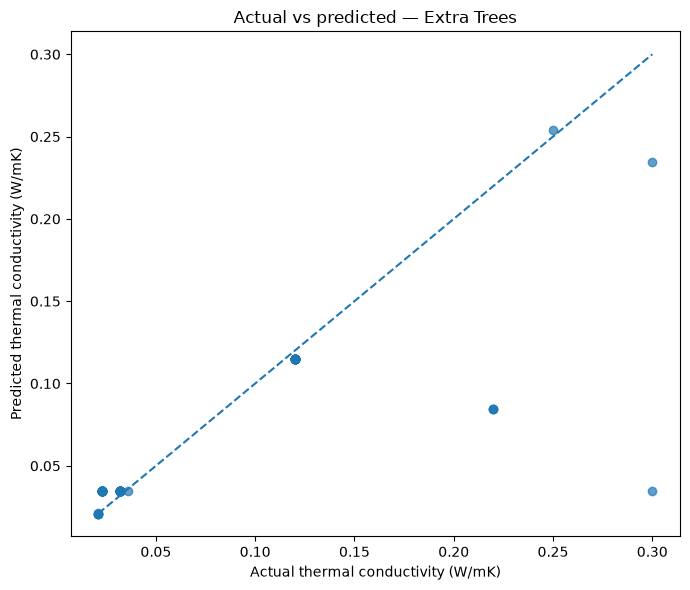

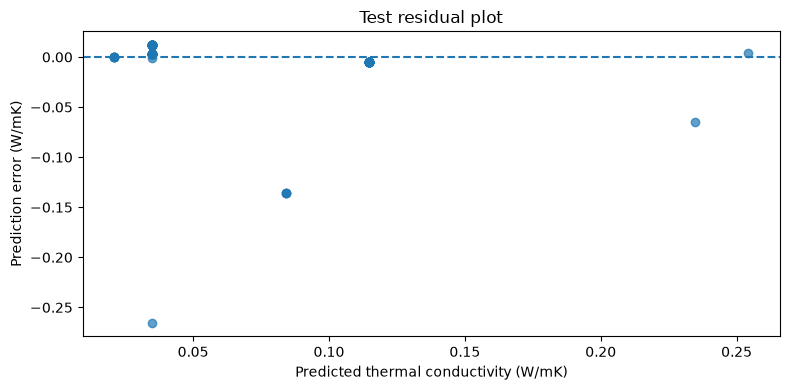

,absolute_error_W_mK
count,114.00000
mean,0.01275
std,0.03230
min,0.00000
50%,0.00524
90%,0.01179
95%,0.01179
max,0.26521


In [11]:
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(y_test, test_predictions, alpha=0.7)
min_value = min(float(y_test.min()), float(np.min(test_predictions)))
max_value = max(float(y_test.max()), float(np.max(test_predictions)))
ax.plot([min_value, max_value], [min_value, max_value], linestyle="--")
ax.set_xlabel("Actual thermal conductivity (W/mK)")
ax.set_ylabel("Predicted thermal conductivity (W/mK)")
ax.set_title(f"Actual vs predicted — {best_model_name}")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(test_predictions, test_results["prediction_error_W_mK"], alpha=0.7)
ax.axhline(0, linestyle="--")
ax.set_xlabel("Predicted thermal conductivity (W/mK)")
ax.set_ylabel("Prediction error (W/mK)")
ax.set_title("Test residual plot")
plt.tight_layout()
plt.show()

display(
    test_results["absolute_error_W_mK"]
    .describe(percentiles=[0.5, 0.9, 0.95])
    .to_frame("absolute_error_W_mK")
    .round(5)
)

### Outcome and conclusion

The test absolute-error summary is:

| Measure | Absolute error (W/mK) |
|---|---:|
| Median | 0.00524 |
| 90th percentile | 0.01179 |
| 95th percentile | 0.01179 |
| Maximum | 0.26521 |
| Mean | 0.01275 |

Some test predictions are notably inaccurate. For example, three displayed records have an actual conductivity of **0.220 W/mK** and a prediction of approximately **0.08435 W/mK**, an absolute error of **0.13565 W/mK** each.

**Conclusion:** Many test predictions are relatively close, as shown by the median error, but a small number of large errors strongly affect MAE and RMSE. The actual-versus-predicted and residual plots should be inspected for systematic underprediction of higher-conductivity products. The maximum error is too large to treat the model as a dependable source of declared product data.

## 12. Feature importance or model coefficients

,feature,feature_importance
0,density_kg_m3,0.803959
3,compressive_strength_kPa,0.127261
2,vapour_resistance_factor_mu,0.033994
5,mass_per_area_kg_m2,0.018140
4,tensile_strength_perpendicular_kPa,0.013998
1,specific_heat_J_kgK,0.002647


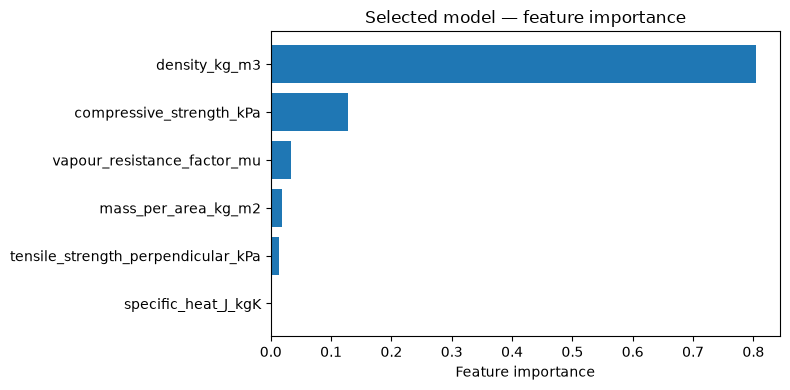

In [12]:
selected_estimator = best_model
if isinstance(best_model, Pipeline):
    final_step = best_model.steps[-1][1]
else:
    final_step = best_model

if hasattr(final_step, "feature_importances_"):
    importance_values = final_step.feature_importances_
    importance_label = "feature_importance"
    feature_effects = pd.DataFrame({
        "feature": feature_columns,
        importance_label: importance_values
    }).sort_values(importance_label, ascending=False)
    display(feature_effects)
    plt.figure(figsize=(8, 4))
    plt.barh(feature_effects["feature"], feature_effects[importance_label])
    plt.gca().invert_yaxis()
    plt.xlabel("Feature importance")
    plt.title("Selected model — feature importance")
    plt.tight_layout()
    plt.show()
elif hasattr(final_step, "coef_"):
    coefficients = np.ravel(final_step.coef_)
    feature_effects = pd.DataFrame({
        "feature": feature_columns,
        "coefficient": coefficients
    }).sort_values("coefficient", key=np.abs, ascending=False)
    display(feature_effects)
else:
    feature_effects = pd.DataFrame(columns=["feature", "importance"])
    print("The selected model does not expose built-in feature importance or coefficients.")

### Outcome and conclusion — actual feature importance

| Feature | Importance |
|---|---:|
| Density | **80.40%** |
| Compressive strength | 12.73% |
| Vapour resistance factor | 3.40% |
| Mass per area | 1.81% |
| Tensile strength | 1.40% |
| Specific heat | 0.26% |

**Conclusion:** The selected Extra Trees model relies heavily on density. However, density is missing in 85.3% of the modelling records and is median-imputed where absent. This makes the importance result something to investigate rather than a simple statement that density is available and decisive for most products. Feature importance describes the fitted model's use of inputs; it does not establish physical causation.

## 13. Save model, predictions and evaluation reports

In [13]:
MODEL_DIR = PROJECT_ROOT / "06_AI_Performance_Engine" / "02_ML_Engine" / "03_Models" / "thermal_prediction"
REPORT_DIR = PROJECT_ROOT / "06_AI_Performance_Engine" / "02_ML_Engine" / "04_Evaluation" / "reports"
FIGURE_DIR = PROJECT_ROOT / "06_AI_Performance_Engine" / "02_ML_Engine" / "04_Evaluation" / "figures"

for folder in [MODEL_DIR, REPORT_DIR, FIGURE_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

model_path = MODEL_DIR / "thermal_conductivity_regressor_v1.joblib"
comparison_path = REPORT_DIR / "thermal_regression_validation_comparison_v1.csv"
predictions_path = REPORT_DIR / "thermal_regression_test_predictions_v1.csv"
metrics_path = REPORT_DIR / "thermal_regression_test_metrics_v1.json"
features_path = REPORT_DIR / "thermal_regression_feature_effects_v1.csv"

joblib.dump(best_model, model_path)
validation_comparison.to_csv(comparison_path, index=False)
test_results.to_csv(predictions_path, index=True)
feature_effects.to_csv(features_path, index=False)

summary = {
    "experiment": "Thermal conductivity regression",
    "dataset_version": "v1.5.0",
    "target": TARGET,
    "target_unit": "W/mK",
    "features": feature_columns,
    "excluded_leakage_columns": sorted(LEAKAGE_COLUMNS),
    "split_source": SPLIT_COL,
    "training_records": int(len(train_df)),
    "validation_records": int(len(val_df)),
    "test_records": int(len(test_df)),
    "candidate_models": list(models.keys()),
    "selected_model": best_model_name,
    "selection_rule": "Lowest validation MAE; validation RMSE as tie-breaker",
    "test_metrics": {k: float(v) for k, v in test_metrics.items()},
    "warning": (
        "Predictions are exploratory estimates, not verified manufacturer values. "
        "Do not replace declared product properties or engineering calculations."
    )
}
metrics_path.write_text(json.dumps(summary, indent=2), encoding="utf-8")

print("Saved selected model:", model_path)
print("Saved validation comparison:", comparison_path)
print("Saved test predictions:", predictions_path)
print("Saved test metrics:", metrics_path)
print("Saved feature effects:", features_path)

Saved selected model: D:\02_LEARNING\02_Masters_IAAC_AI_Architecture\10-Term_01\03-Research Studio\SpecSynth_AI\06_AI_Performance_Engine\02_ML_Engine\03_Models\thermal_prediction\thermal_conductivity_regressor_v1.joblib
Saved validation comparison: D:\02_LEARNING\02_Masters_IAAC_AI_Architecture\10-Term_01\03-Research Studio\SpecSynth_AI\06_AI_Performance_Engine\02_ML_Engine\04_Evaluation\reports\thermal_regression_validation_comparison_v1.csv
Saved test predictions: D:\02_LEARNING\02_Masters_IAAC_AI_Architecture\10-Term_01\03-Research Studio\SpecSynth_AI\06_AI_Performance_Engine\02_ML_Engine\04_Evaluation\reports\thermal_regression_test_predictions_v1.csv
Saved test metrics: D:\02_LEARNING\02_Masters_IAAC_AI_Architecture\10-Term_01\03-Research Studio\SpecSynth_AI\06_AI_Performance_Engine\02_ML_Engine\04_Evaluation\reports\thermal_regression_test_metrics_v1.json
Saved feature effects: D:\02_LEARNING\02_Masters_IAAC_AI_Architecture\10-Term_01\03-Research Studio\SpecSynth_AI\06_AI_Perform

### Outcome and conclusion

The notebook successfully saved the selected Extra Trees model, validation comparison, test predictions, test metrics and feature-importance report in the ML Engine folders.

**Conclusion:** The experiment is reproducible and its artefacts are available for further review. Saving the model does not mean it is approved for Revit or user-facing predictions.

# Final conclusion — Thermal Conductivity Prediction

This experiment compared seven regression models using the SpecSynth v1.5.0 product-variant dataset. The target was `target_thermal_conductivity_W_mK` in W/mK.

## What worked

- The correct dataset loaded: 1,941 rows and 47 columns.
- The original train/validation/test split was preserved.
- 1,781 records had a usable target: 1,493 training, 174 validation and 114 test.
- Thickness, thermal resistance and thermal conductivity were excluded from model inputs to prevent direct mathematical target leakage.
- Seven regression candidates were trained and compared.
- The selected Extra Trees model and evaluation artefacts were saved successfully.

## Model comparison

Extra Trees had the lowest validation MAE at **0.00306 W/mK**, so it was selected under the notebook's MAE-first rule. Gradient Boosting was a close alternative: it had a validation MAE of 0.00336 W/mK, but better RMSE (0.00869 W/mK) and R² (0.89852).

The selected Extra Trees model achieved test MAE **0.01275 W/mK**, test RMSE **0.03459 W/mK** and test R² **0.67182**.

## Important limitations

1. **Validation-to-test performance gap:** MAE increased from 0.00306 to 0.01275 W/mK. The model's test performance is therefore notably weaker than its validation performance.
2. **Different target distribution:** the test mean conductivity was 0.0608 W/mK, compared with 0.0387 in training and 0.0355 in validation.
3. **Sparse input properties:** selected features have between 63.2% and 93.1% missingness. Median imputation is necessary but reduces the amount of product-specific information available.
4. **Large individual errors:** the maximum test absolute error was 0.26521 W/mK. Several high-conductivity records were substantially underpredicted.
5. **Feature importance needs care:** density accounts for 80.40% of the model's feature importance, but density is missing for 85.3% of records and is imputed for many rows.

## Recommendation for SpecSynth AI

**Step 7 is complete as an initial model-comparison experiment, but the selected model is not ready for production integration.**

Keep Extra Trees as the current validation-selected candidate and retain Gradient Boosting as an alternative. Before either model is used in a user-facing workflow, investigate the large test errors, examine performance by material family and product group, and test whether the model's predictions remain reliable for products with sparse input properties.

Predicted conductivity must be clearly labelled as an AI estimate. It must not overwrite manufacturer-declared conductivity, replace missing verified product information, or be treated as a compliance result. SpecSynth's verified product data and ThermalEngine calculations remain authoritative.

**Final takeaway:** The experiment demonstrates that the dataset contains useful predictive signals, but current test errors and sparse input coverage are too significant to trust the model as a product specification source. The next stage should focus on deeper validation and reliability checks before deployment.